# 3 · Camada Gold — Análise das Viagens a Serviço (1º semestre/2025)

Este notebook é a última etapa do pipeline (Arquitetura Medallion):

| Camada | Onde está | O que contém |
|---|---|---|
| Raw | `raw_*` | cópia fiel dos CSVs (tudo texto) |
| Silver | `silver_*` | dados limpos, tipados, com PK/FK/constraints |
| **Gold** | **este notebook + `gold_*` / `vw_gold_*`** | **métricas de negócio e gráficos** |

**Parte A** — 3 perguntas respondidas direto da Silver (SQL → tabela → gráfico).
**Parte B** — Camada Gold agregada (JOIN + GROUP BY), criada como **TABELA** e como **VIEW**, respondendo as outras 4 perguntas.

> Pré-requisito: ter rodado `0_criar_banco.sql`, `1_extrair.py` e `2_transformar.py`.

In [1]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from banco import consultar, executar
from config import IMG_DIR

IMG_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})
COR = "#2a6f97"

In [2]:
def brl(valor):
    """Formata número no padrão monetário brasileiro: R$ 1.234,56"""
    texto = f"{float(valor):,.2f}"
    return "R$ " + texto.replace(",", "X").replace(".", ",").replace("X", ".")


def num(valor, casas=0):
    """Formata número no padrão brasileiro: 1.354 | 39,7"""
    texto = f"{float(valor):,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


def sql_df(sql, colunas_numericas=()):
    """Roda a consulta e converte DECIMAL -> float para poder plotar."""
    df = consultar(sql)
    for coluna in colunas_numericas:
        df[coluna] = pd.to_numeric(df[coluna])
    return df


def quebrar(rotulo, largura=35):
    """Quebra rótulos longos (nomes de órgãos) em várias linhas."""
    return "\n".join(textwrap.wrap(str(rotulo), largura)) or "(vazio)"


def grafico_barras(df, categoria, valor, titulo, rotulo_x, rotulo_y,
                   legenda, arquivo, horizontal=True, moeda=True):
    """Gráfico de barras padronizado: título, eixos nomeados, legenda,
    rótulo de valor em cada barra e exportação para img/."""
    fig, ax = plt.subplots()
    rotulos = [quebrar(r) for r in df[categoria]]
    formatar = brl if moeda else (lambda v: f"{num(v)}".replace(",", "."))
    if horizontal:
        barras = ax.barh(rotulos[::-1], df[valor][::-1], color=COR,
                         label=legenda)
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(
            lambda v, _: formatar(v)))
    else:
        barras = ax.bar(rotulos, df[valor], color=COR, label=legenda)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda v, _: formatar(v)))
    ax.bar_label(barras, labels=[formatar(v) for v in
                                 (df[valor][::-1] if horizontal else df[valor])],
                 padding=3, fontsize=9)
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.set_xlabel(rotulo_x)
    ax.set_ylabel(rotulo_y)
    ax.legend(loc="lower right" if horizontal else "upper right")
    ax.margins(x=0.15) if horizontal else ax.margins(y=0.15)
    fig.tight_layout()
    fig.savefig(IMG_DIR / arquivo, dpi=120)
    plt.show()

## 0. Conferência da camada Silver
Antes de analisar, confirmamos volumes e que não há registros órfãos (integridade referencial).

In [3]:
volumes = sql_df('''
    SELECT 'silver_viagem' AS tabela, COUNT(*) AS linhas FROM silver_viagem
    UNION ALL SELECT 'silver_pagamento', COUNT(*) FROM silver_pagamento
    UNION ALL SELECT 'silver_passagem', COUNT(*) FROM silver_passagem
    UNION ALL SELECT 'silver_trecho', COUNT(*) FROM silver_trecho
''')
orfaos = sql_df('''
    SELECT COUNT(*) AS pagamentos_sem_viagem
    FROM silver_pagamento p
    LEFT JOIN silver_viagem v ON v.id_viagem = p.id_viagem
    WHERE v.id_viagem IS NULL
''')
display(volumes, orfaos)

,tabela,linhas
0,silver_passagem,167210
1,silver_pagamento,568811
2,silver_viagem,341860
3,silver_trecho,763349


,pagamentos_sem_viagem
0,0


---
# Parte A — Perguntas respondidas diretamente da Silver

## Pergunta 1 — Quais os 5 órgãos com maior custo total?
Custo total = soma de `valor_total` (diárias + passagens + outros gastos − devolução) por órgão superior.

In [4]:
q1 = sql_df('''
    SELECT nome_orgao_superior,
           COUNT(*)                   AS qtd_viagens,
           SUM(valor_total)           AS custo_total,
           ROUND(AVG(valor_total), 2) AS custo_medio_viagem
    FROM silver_viagem
    GROUP BY nome_orgao_superior
    ORDER BY custo_total DESC
    LIMIT 5
''', ["custo_total", "custo_medio_viagem"])
q1

,nome_orgao_superior,qtd_viagens,custo_total,custo_medio_viagem
0,Ministério da Justiça e Segurança Pública,75742,4.869331e+08,6428.84
1,Ministério da Defesa,61912,1.560703e+08,2520.84
2,Ministério da Educação,65295,1.112913e+08,1704.44
3,Ministério do Meio Ambiente e Mudança do Clima,19413,4.969771e+07,2560.02
4,Ministério da Previdência Social,8190,4.041731e+07,4934.96


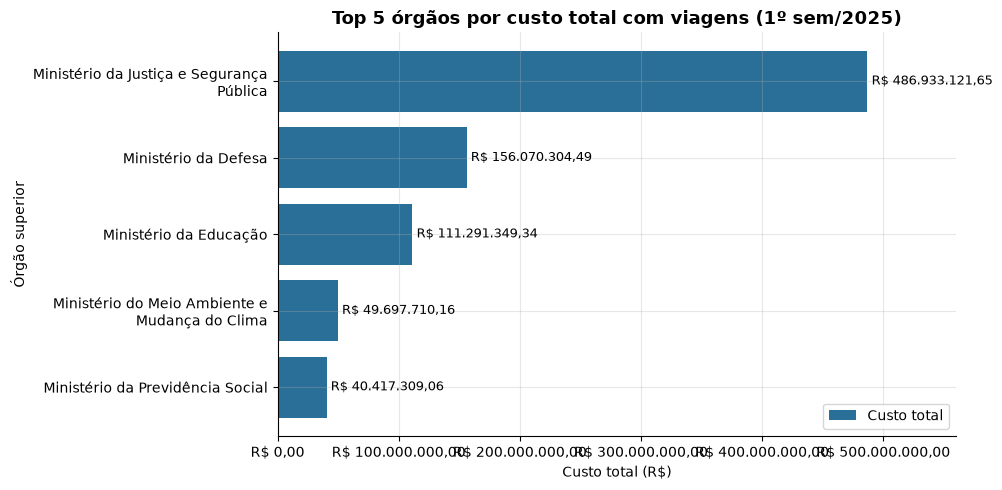

Resposta: o órgão de maior custo é Ministério da Justiça e Segurança Pública (R$ 486.933.121,65).
Os 5 maiores somam 71.1% de todo o gasto com viagens do período.


In [5]:
grafico_barras(q1, "nome_orgao_superior", "custo_total",
               "Top 5 órgãos por custo total com viagens (1º sem/2025)",
               "Custo total (R$)", "Órgão superior", "Custo total",
               "q1_top5_orgaos_custo.png")

total_geral = float(consultar("SELECT SUM(valor_total) AS t FROM silver_viagem")["t"][0])
participacao = q1["custo_total"].sum() / total_geral * 100
print(f"Resposta: o órgão de maior custo é {q1.iloc[0, 0]} ({brl(q1.iloc[0]['custo_total'])}).")
print(f"Os 5 maiores somam {participacao:.1f}% de todo o gasto com viagens do período.")

> **Interpretação (escreva após rodar):** o gasto está concentrado em poucos órgãos? O custo vem de muitas viagens ou de viagens caras (compare `qtd_viagens` com `custo_medio_viagem`)?

## Pergunta 2 — Quais os 3 destinos com maior custo médio por viagem?
Usamos o campo `destinos` da viagem. Como destinos com **uma única viagem** distorcem a média,
mostramos também a versão com um mínimo de viagens (amostra mais confiável).

In [6]:
q2 = sql_df('''
    SELECT destinos,
           COUNT(*)                   AS qtd_viagens,
           ROUND(AVG(valor_total), 2) AS custo_medio
    FROM silver_viagem
    WHERE destinos IS NOT NULL
    GROUP BY destinos
    ORDER BY custo_medio DESC
    LIMIT 3
''', ["custo_medio"])

MIN_VIAGENS = 30
q2_robusta = sql_df(f'''
    SELECT destinos,
           COUNT(*)                   AS qtd_viagens,
           ROUND(AVG(valor_total), 2) AS custo_medio
    FROM silver_viagem
    WHERE destinos IS NOT NULL
    GROUP BY destinos
    HAVING COUNT(*) >= {MIN_VIAGENS}
    ORDER BY custo_medio DESC
    LIMIT 3
''', ["custo_medio"])
display(q2, q2_robusta)

,destinos,qtd_viagens,custo_medio
0,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ",1,245852.80
1,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, ...",1,216729.36
2,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasíl...",1,207220.14


,destinos,qtd_viagens,custo_medio
0,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",91,105470.37
1,"Brasília/DF, Brasília/DF, Brasília/DF",88,100317.26
2,"Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF, Brasília/DF",47,97736.69


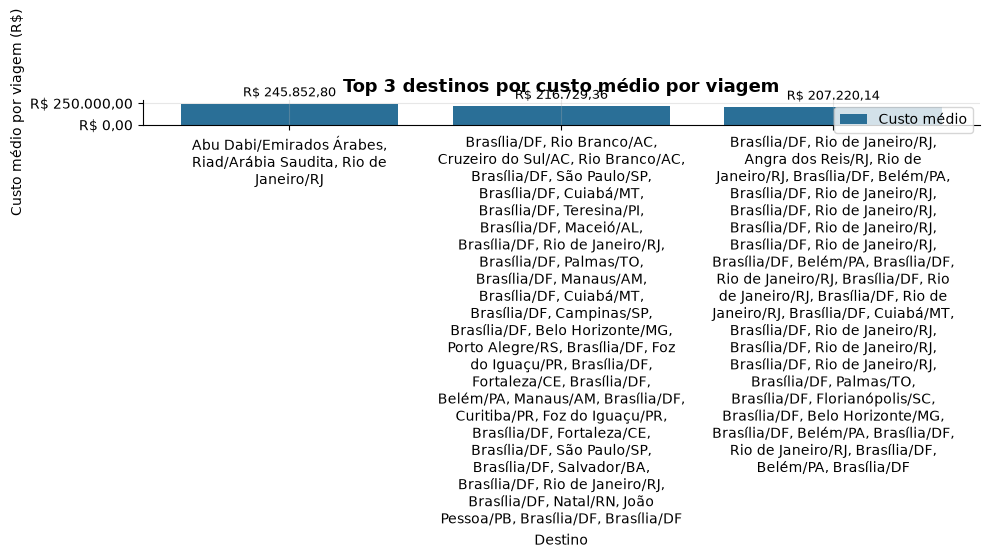

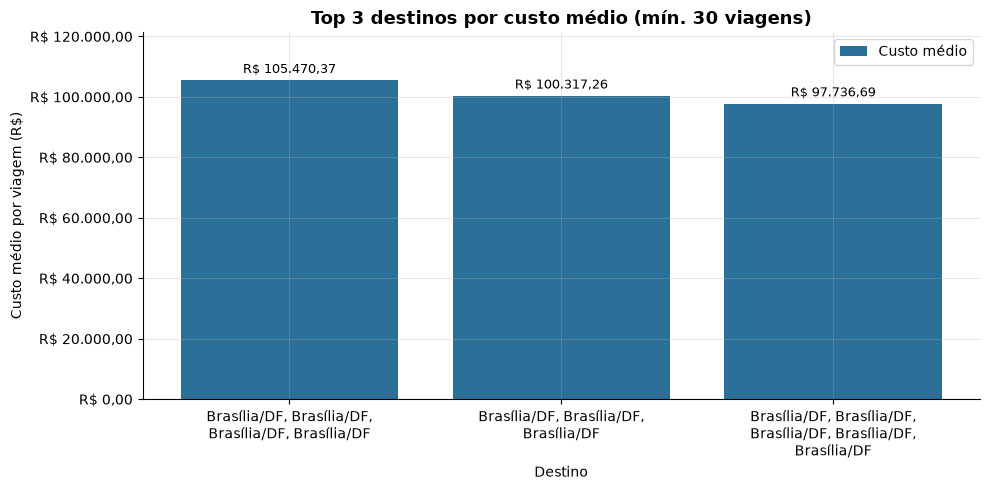

Resposta: maior custo médio -> Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ (R$ 245.852,80, 1 viagem(ns)).


In [7]:
grafico_barras(q2, "destinos", "custo_medio",
               "Top 3 destinos por custo médio por viagem",
               "Destino", "Custo médio por viagem (R$)", "Custo médio",
               "q2_top3_destinos_custo_medio.png", horizontal=False)

grafico_barras(q2_robusta, "destinos", "custo_medio",
               f"Top 3 destinos por custo médio (mín. {MIN_VIAGENS} viagens)",
               "Destino", "Custo médio por viagem (R$)", "Custo médio",
               "q2b_top3_destinos_robusto.png", horizontal=False)

print(f"Resposta: maior custo médio -> {q2.iloc[0]['destinos']} "
      f"({brl(q2.iloc[0]['custo_medio'])}, {q2.iloc[0]['qtd_viagens']} viagem(ns)).")

> **Interpretação:** os destinos do topo são internacionais? Quantas viagens sustentam cada média? O que muda quando exigimos um mínimo de viagens?

In [8]:
print(q2[["destinos", "qtd_viagens", "custo_medio"]].to_string(index=False))
print()
print("Com no mínimo 30 viagens por destino:")
print(q2_robusta.to_string(index=False))

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      destinos  qtd_viagens  custo_medio
                                                                                                                                                                                                                                                                                                                               

In [9]:
q2_trecho = sql_df('''
    SELECT t.destino_cidade || ' / ' || t.destino_uf AS destino,
           COUNT(*)                     AS qtd_viagens,
           ROUND(AVG(v.valor_total), 2) AS custo_medio
    FROM silver_viagem v
    JOIN silver_trecho t ON t.id_viagem = v.id_viagem
                        AND t.sequencia_trecho = 1
    WHERE t.destino_cidade IS NOT NULL
    GROUP BY 1
    HAVING COUNT(*) >= 30
    ORDER BY custo_medio DESC
    LIMIT 5
''', ["custo_medio"])
q2_trecho

,destino,qtd_viagens,custo_medio
0,Jacareacanga / Pará,95,44565.53
1,Tucumã / Pará,101,34238.07
2,Itaituba / Pará,185,27145.19
3,Guaíra / Paraná,108,25686.37
4,Atalaia do Norte / Amazonas,84,18999.64


## Pergunta 3 — Qual a viagem de maior duração e seu custo total?
`duracao_dias` foi calculada na Silver como `data_fim − data_inicio + 1`.

In [10]:
q3 = sql_df('''
    SELECT id_viagem, nome_orgao_superior, cargo, data_inicio, data_fim,
           duracao_dias, destinos, valor_total
    FROM silver_viagem
    WHERE duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC, valor_total DESC
    LIMIT 10
''', ["duracao_dias", "valor_total"])
q3

,id_viagem,nome_orgao_superior,cargo,data_inicio,data_fim,duracao_dias,destinos,valor_total
0,0000000000020699856,Ministério da Previdência Social,TECNICO DO SEGURO SOCIAL,2025-01-13,2026-01-31,384,Mogi Mirim/SP,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-02,2026-01-15,379,Informações protegidas por sigilo,120650.00
2,0000000000020793492,Ministério da Justiça e Segurança Pública,Informações protegidas por sigilo,2025-01-11,2026-01-15,370,Informações protegidas por sigilo,113382.50
3,0000000000020774569,Ministério da Educação,PROFESSOR DO MAGISTERIO SUPERIOR,2025-02-26,2026-03-02,370,Bariloche/Argentina,0.00
4,0000000000020592696,Ministério da Justiça e Segurança Pública,NaN,2025-01-01,2026-01-02,367,"Brasília/DF, Belo Horizonte/MG, Brasília/DF, Fortaleza/CE, Goiânia/GO, Brasí...",159044.90
5,0000000000020685666,Ministério da Justiça e Segurança Pública,NaN,2025-01-01,2026-01-02,367,"Brasília/DF, Brasília/DF, Rio de Janeiro/RJ, Brasília/DF, Brasília/DF",124312.50
6,0000000000020589962,Ministério da Educação,PROFESSOR DO MAGISTERIO SUPERIOR,2025-02-23,2026-02-23,366,Aberdeen/Reino Unido,0.00
7,0000000000020732132,Ministério da Educação,PROFESSOR DO MAGISTERIO SUPERIOR,2025-03-31,2026-03-31,366,Angers/França,0.00
8,0000000000020557147,Ministério da Justiça e Segurança Pública,NaN,2025-01-01,2025-12-31,365,"Brasília/DF, Rio Branco/AC, Cruzeiro do Sul/AC, Rio Branco/AC, Brasília/DF, ...",216729.36
9,0000000000020649880,Ministério da Justiça e Segurança Pública,NaN,2025-01-01,2025-12-31,365,"Brasília/DF, Rio de Janeiro/RJ, Angra dos Reis/RJ, Rio de Janeiro/RJ, Brasíl...",207220.14


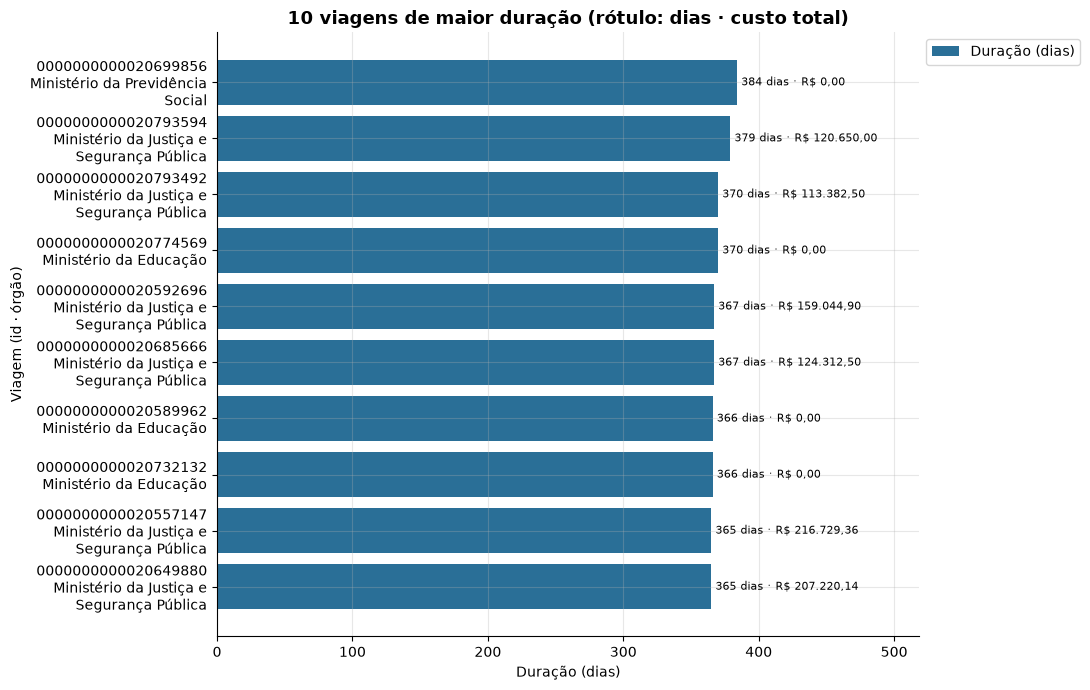

Resposta: a viagem 0000000000020699856 (Ministério da Previdência Social) durou 384 dias, de 2025-01-13 a 2026-01-31, com custo total de R$ 0,00.


In [11]:
fig, ax = plt.subplots(figsize=(11, 7))
rotulos = [f"{r.id_viagem}\n{quebrar(r.nome_orgao_superior, 30)}" for r in q3.itertuples()]
barras = ax.barh(rotulos[::-1], q3["duracao_dias"][::-1], color=COR,
                 label="Duração (dias)")
ax.bar_label(barras, labels=[f"{d:.0f} dias · {brl(v)}" for d, v in
                             zip(q3["duracao_dias"][::-1], q3["valor_total"][::-1])],
             padding=3, fontsize=8)
ax.set_title("10 viagens de maior duração (rótulo: dias · custo total)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Duração (dias)")
ax.set_ylabel("Viagem (id · órgão)")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.margins(x=0.35)
fig.tight_layout()
fig.savefig(IMG_DIR / "q3_viagens_maior_duracao.png", dpi=120)
plt.show()

top = q3.iloc[0]
print(f"Resposta: a viagem {top['id_viagem']} ({top['nome_orgao_superior']}) durou "
      f"{top['duracao_dias']:.0f} dias, de {top['data_inicio']} a {top['data_fim']}, "
      f"com custo total de {brl(top['valor_total'])}.")

> **Interpretação:** a viagem mais longa é também cara? Duração alta com custo baixo pode indicar curso/missão com custeio diferente ou dado a ser auditado.

In [12]:
q3_extra = sql_df('''
    SELECT id_viagem, nome_orgao_superior, data_inicio, data_fim,
           duracao_dias, valor_total
    FROM silver_viagem
    WHERE duracao_dias IS NOT NULL AND valor_total > 0
    ORDER BY duracao_dias DESC
    LIMIT 5
''', ["duracao_dias", "valor_total"])
display(q3_extra)

longas = sql_df('''
    SELECT COUNT(*) AS viagens_acima_180_dias,
           SUM(CASE WHEN valor_total = 0 THEN 1 ELSE 0 END) AS com_custo_zero
    FROM silver_viagem
    WHERE duracao_dias > 180
''')
display(longas)

,id_viagem,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,379,120650.00
1,0000000000020793492,Ministério da Justiça e Segurança Pública,2025-01-11,2026-01-15,370,113382.50
2,0000000000020592696,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,159044.90
3,0000000000020685666,Ministério da Justiça e Segurança Pública,2025-01-01,2026-01-02,367,124312.50
4,0000000000020536291,Ministério da Justiça e Segurança Pública,2025-01-01,2025-12-31,365,137678.63


,viagens_acima_180_dias,com_custo_zero
0,2273,52


In [13]:
hipotese = sql_df('''
    SELECT CASE WHEN motivo ILIKE '%força nacional%'
                  OR motivo ILIKE '%forca nacional%' THEN 'Menciona Força Nacional'
                ELSE 'Outros motivos' END AS grupo,
           COUNT(*)                   AS qtd_viagens,
           ROUND(AVG(duracao_dias), 1) AS duracao_media,
           SUM(valor_total)           AS custo_total
    FROM silver_viagem
    WHERE nome_orgao_superior = 'Ministério da Justiça e Segurança Pública'
      AND duracao_dias > 180
    GROUP BY 1
''', ["custo_total"])
hipotese

,grupo,qtd_viagens,duracao_media,custo_total
0,Menciona Força Nacional,1351,328.9,1.469315e+08
1,Outros motivos,838,331.0,9.443237e+07


---
# Parte B — Camada Gold agregada (JOIN + GROUP BY)

Cada agregação é criada **duas vezes** no banco:
* **VIEW** `vw_gold_*` → a regra de negócio, sempre atualizada (calculada na hora da consulta);
* **TABELA** `gold_*` → uma "foto" materializada da view, rápida para dashboards.

Todas fazem **JOIN** entre uma tabela filha e `silver_viagem` (para trazer órgão superior e urgência) e **GROUP BY** pela dimensão de negócio.

In [14]:
GOLD = {
    "gold_pagamento_por_tipo": """
        SELECT p.tipo_pagamento,
               COUNT(*)                              AS qtd_pagamentos,
               COUNT(DISTINCT p.id_viagem)           AS qtd_viagens,
               COUNT(DISTINCT v.nome_orgao_superior) AS qtd_orgaos,
               SUM(p.valor)                          AS valor_total,
               ROUND(AVG(p.valor), 2)                AS valor_medio
        FROM silver_pagamento p
        JOIN silver_viagem v ON v.id_viagem = p.id_viagem
        GROUP BY p.tipo_pagamento""",

    "gold_trecho_por_transporte": """
        SELECT t.meio_transporte,
               COUNT(*)                              AS qtd_trechos,
               COUNT(DISTINCT t.id_viagem)           AS qtd_viagens,
               COUNT(DISTINCT v.nome_orgao_superior) AS qtd_orgaos,
               SUM(t.numero_diarias)                 AS total_diarias
        FROM silver_trecho t
        JOIN silver_viagem v ON v.id_viagem = t.id_viagem
        WHERE t.meio_transporte IS NOT NULL
        GROUP BY t.meio_transporte""",

    "gold_trecho_por_uf_destino": """
        SELECT t.destino_uf,
               COUNT(*)                              AS qtd_trechos,
               COUNT(DISTINCT t.id_viagem)           AS qtd_viagens,
               COUNT(DISTINCT v.nome_orgao_superior) AS qtd_orgaos
        FROM silver_trecho t
        JOIN silver_viagem v ON v.id_viagem = t.id_viagem
        WHERE t.destino_uf IS NOT NULL
        GROUP BY t.destino_uf""",

    "gold_orgao_pagador": """
        SELECT p.nome_orgao_pagador,
               SUM(p.valor)                          AS valor_total_pago,
               COUNT(*)                              AS qtd_pagamentos,
               COUNT(DISTINCT p.id_viagem)           AS qtd_viagens,
               ROUND(SUM(p.valor) / COUNT(DISTINCT p.id_viagem), 2)
                                                     AS valor_medio_por_viagem,
               COUNT(DISTINCT CASE WHEN v.viagem_urgente = 'Sim'
                                   THEN v.id_viagem END) AS qtd_viagens_urgentes
        FROM silver_pagamento p
        JOIN silver_viagem v ON v.id_viagem = p.id_viagem
        WHERE p.nome_orgao_pagador IS NOT NULL
        GROUP BY p.nome_orgao_pagador""",
}


def criar_gold(nome_tabela, select_sql):
    """Cria a VIEW vw_<nome> e materializa a TABELA <nome> a partir dela."""
    view = f"vw_{nome_tabela}"
    # Apagar e recriar (em vez de CREATE OR REPLACE) evita erro no PostgreSQL
    # quando as colunas da view mudam entre uma execução e outra.
    executar(f"DROP VIEW IF EXISTS {view}")
    executar(f"CREATE VIEW {view} AS {select_sql}")
    executar(f"DROP TABLE IF EXISTS {nome_tabela}")
    executar(f"CREATE TABLE {nome_tabela} AS SELECT * FROM {view}")
    linhas = consultar(f"SELECT COUNT(*) AS n FROM {nome_tabela}")["n"][0]
    print(f"OK  {view} (VIEW)  +  {nome_tabela} (TABELA): {linhas} linhas")


for nome, select_sql in GOLD.items():
    criar_gold(nome, select_sql)

OK  vw_gold_pagamento_por_tipo (VIEW)  +  gold_pagamento_por_tipo (TABELA): 4 linhas
OK  vw_gold_trecho_por_transporte (VIEW)  +  gold_trecho_por_transporte (TABELA): 8 linhas
OK  vw_gold_trecho_por_uf_destino (VIEW)  +  gold_trecho_por_uf_destino (TABELA): 28 linhas
OK  vw_gold_orgao_pagador (VIEW)  +  gold_orgao_pagador (TABELA): 216 linhas


## Pergunta 4 — Qual o tipo de pagamento com maior valor médio?

In [15]:
q4 = sql_df('''
    SELECT tipo_pagamento, qtd_pagamentos, valor_total, valor_medio
    FROM gold_pagamento_por_tipo
    ORDER BY valor_medio DESC
''', ["valor_total", "valor_medio"])
q4

,tipo_pagamento,qtd_pagamentos,valor_total,valor_medio
0,PASSAGEM,186008,3.453756e+08,1856.78
1,DIÁRIAS,366351,6.585353e+08,1797.55
2,Serviço correlato: seguro,4882,2.185792e+06,447.72
3,RESTITUIÇÃO,11570,2.842679e+06,245.69


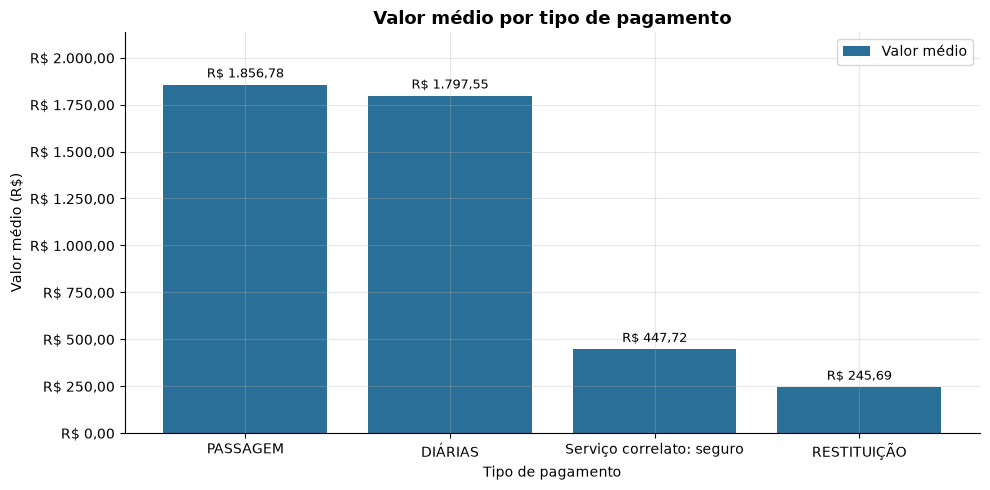

Resposta: 'PASSAGEM' tem o maior valor médio (R$ 1.856,78 em 186.008 pagamentos).


In [16]:
grafico_barras(q4, "tipo_pagamento", "valor_medio",
               "Valor médio por tipo de pagamento",
               "Tipo de pagamento", "Valor médio (R$)", "Valor médio",
               "q4_valor_medio_tipo_pagamento.png", horizontal=False)
print(f"Resposta: '{q4.iloc[0]['tipo_pagamento']}' tem o maior valor médio "
      f"({brl(q4.iloc[0]['valor_medio'])} em {num(q4.iloc[0]['qtd_pagamentos'])} pagamentos).")

> **Interpretação:** o tipo com maior valor médio é também o de maior volume total? Compare `valor_medio` com `valor_total`.

## Pergunta 5 — Qual o meio de transporte mais usado nos trechos?

In [17]:
q5 = sql_df('''
    SELECT meio_transporte, qtd_trechos, qtd_viagens, total_diarias
    FROM gold_trecho_por_transporte
    ORDER BY qtd_trechos DESC
''', ["qtd_trechos"])
q5["percentual"] = (q5["qtd_trechos"] / q5["qtd_trechos"].sum() * 100).round(1)
q5

,meio_transporte,qtd_trechos,qtd_viagens,total_diarias,percentual
0,Veículo Oficial,386424,153018,822390.60,50.6
1,Aéreo,232666,114214,402029.30,30.5
2,Rodoviário,64970,31126,181885.00,8.5
3,Veículo Próprio,42846,19356,257397.00,5.6
4,Inválido,26659,20542,40680.50,3.5
5,Fluvial,8429,4070,20279.00,1.1
6,Ferroviário,874,459,3276.20,0.1
7,Marítimo,481,230,431.00,0.1


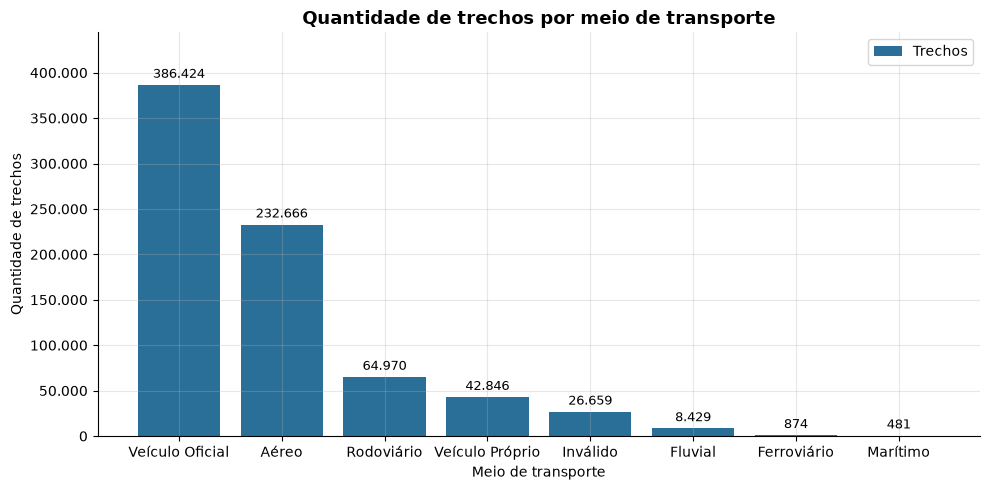

Resposta: 'Veículo Oficial' é o mais usado, com 386.424 trechos (50,6% do total).


In [18]:
grafico_barras(q5, "meio_transporte", "qtd_trechos",
               "Quantidade de trechos por meio de transporte",
               "Meio de transporte", "Quantidade de trechos", "Trechos",
               "q5_trechos_por_transporte.png", horizontal=False, moeda=False)
print(f"Resposta: '{q5.iloc[0]['meio_transporte']}' é o mais usado, com "
      f"{num(q5.iloc[0]['qtd_trechos'])} trechos ({num(q5.iloc[0]['percentual'], 1)}% do total).")

## Pergunta 6 — Qual UF de destino aparece em mais trechos?

In [19]:
q6 = sql_df('''
    SELECT destino_uf, qtd_trechos, qtd_viagens, qtd_orgaos
    FROM gold_trecho_por_uf_destino
    ORDER BY qtd_trechos DESC
    LIMIT 10
''', ["qtd_trechos"])
q6

,destino_uf,qtd_trechos,qtd_viagens,qtd_orgaos
0,São Paulo,82722,46392,35
1,Distrito Federal,79962,72297,35
2,Minas Gerais,50965,26891,34
3,Rio de Janeiro,44197,35050,35
4,Paraná,42603,22263,35
5,Pará,40044,18138,34
6,Rio Grande do Sul,38684,20104,34
7,Mato Grosso do Sul,30516,13332,33
8,Bahia,28375,14735,35
9,Pernambuco,28372,16637,35


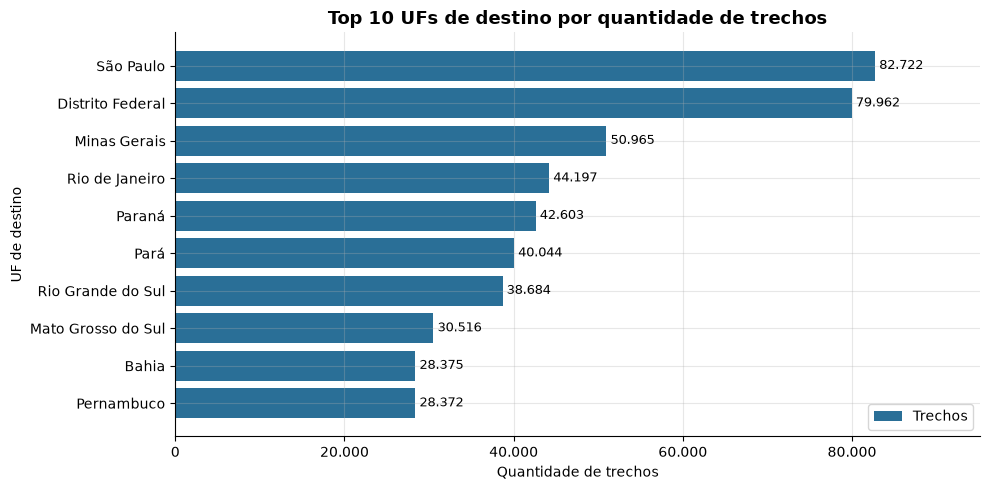

Resposta: São Paulo é a UF de destino com mais trechos (82.722).


In [20]:
grafico_barras(q6, "destino_uf", "qtd_trechos",
               "Top 10 UFs de destino por quantidade de trechos",
               "Quantidade de trechos", "UF de destino", "Trechos",
               "q6_top10_uf_destino.png", moeda=False)
print(f"Resposta: {q6.iloc[0]['destino_uf']} é a UF de destino com mais trechos "
      f"({num(q6.iloc[0]['qtd_trechos'])}).")

> **Interpretação:** o DF lidera por concentrar a administração federal? Quais UFs aparecem logo depois e por quê?

## Pergunta 7 — Qual órgão pagou mais no total?

In [21]:
q7 = sql_df('''
    SELECT nome_orgao_pagador, valor_total_pago, qtd_viagens,
           valor_medio_por_viagem, qtd_viagens_urgentes
    FROM gold_orgao_pagador
    ORDER BY valor_total_pago DESC
    LIMIT 10
''', ["valor_total_pago", "valor_medio_por_viagem"])
q7

,nome_orgao_pagador,valor_total_pago,qtd_viagens,valor_medio_por_viagem,qtd_viagens_urgentes
0,Sigiloso,1.706599e+08,51550,3310.57,0
1,Fundo Nacional de Segurança Pública,1.419117e+08,24116,5884.55,0
2,Comando da Aeronáutica,8.118082e+07,32336,2510.54,0
3,Comando do Exército,3.590138e+07,13285,2702.40,0
4,Instituto Nacional do Seguro Social,3.538535e+07,7264,4871.33,0
5,Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com víncu...,3.464002e+07,9428,3674.16,0
6,Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,3.101087e+07,8809,3520.36,0
7,Ministério das Relações Exteriores - Unidades com vínculo direto,2.558992e+07,1927,13279.67,0
8,Receita Federal do Brasil,2.354834e+07,10063,2340.09,0
9,Ministério da Agricultura e Pecuária - Unidades com vínculo direto,2.234302e+07,10754,2077.65,0


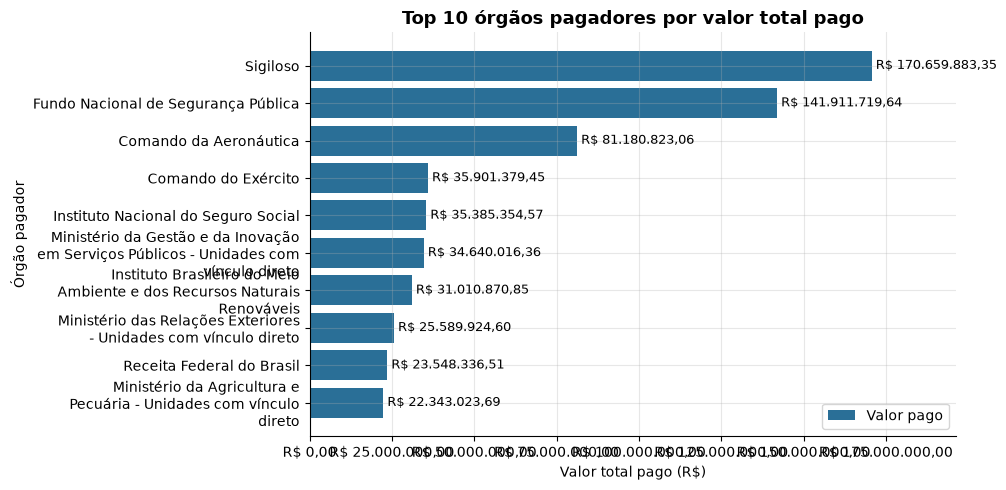

Resposta: Sigiloso foi o órgão que mais pagou: R$ 170.659.883,35.


In [22]:
grafico_barras(q7, "nome_orgao_pagador", "valor_total_pago",
               "Top 10 órgãos pagadores por valor total pago",
               "Valor total pago (R$)", "Órgão pagador", "Valor pago",
               "q7_top10_orgaos_pagadores.png")
print(f"Resposta: {q7.iloc[0]['nome_orgao_pagador']} foi o órgão que mais pagou: "
      f"{brl(q7.iloc[0]['valor_total_pago'])}.")

> **Interpretação:** o órgão que mais pagou (tabela de pagamentos) é o mesmo da Pergunta 1 (custo por órgão superior)? Se não, por quê? (órgão pagador ≠ órgão superior do viajante).

In [23]:
total_pago = float(consultar("SELECT SUM(valor_total_pago) AS t FROM gold_orgao_pagador")["t"][0])
sigiloso = float(q7.loc[q7["nome_orgao_pagador"] == "Sigiloso", "valor_total_pago"].sum())
print(f"'Sigiloso' representa {num(sigiloso / total_pago * 100, 1)}% de todo o valor pago.")

q7_identificados = sql_df('''
    SELECT nome_orgao_pagador, valor_total_pago, qtd_viagens
    FROM gold_orgao_pagador
    WHERE nome_orgao_pagador <> 'Sigiloso'
    ORDER BY valor_total_pago DESC
    LIMIT 5
''', ["valor_total_pago"])

q7_identificados.style.format({"valor_total_pago": brl})

'Sigiloso' representa 16,9% de todo o valor pago.


,nome_orgao_pagador,valor_total_pago,qtd_viagens
0,Fundo Nacional de Segurança Pública,"R$ 141.911.719,64",24116
1,Comando da Aeronáutica,"R$ 81.180.823,06",32336
2,Comando do Exército,"R$ 35.901.379,45",13285
3,Instituto Nacional do Seguro Social,"R$ 35.385.354,57",7264
4,Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com vínculo direto,"R$ 34.640.016,36",9428


---
## Resumo das respostas

In [24]:
resumo = pd.DataFrame([
    ("1. Órgão com maior custo total", q1.iloc[0]["nome_orgao_superior"], brl(q1.iloc[0]["custo_total"])),
    ("2. Destino com maior custo médio", q2.iloc[0]["destinos"], brl(q2.iloc[0]["custo_medio"])),
    ("3. Viagem de maior duração", f"{q3.iloc[0]['id_viagem']} ({q3.iloc[0]['duracao_dias']:.0f} dias)", brl(q3.iloc[0]["valor_total"])),
    ("4. Tipo de pagamento c/ maior média", q4.iloc[0]["tipo_pagamento"], brl(q4.iloc[0]["valor_medio"])),
    ("5. Meio de transporte mais usado", q5.iloc[0]["meio_transporte"], f"{num(q5.iloc[0]['qtd_trechos'])} trechos"),
    ("6. UF de destino com mais trechos", q6.iloc[0]["destino_uf"], f"{num(q6.iloc[0]['qtd_trechos'])} trechos"),
    ("7. Órgão que mais pagou", q7.iloc[0]["nome_orgao_pagador"], brl(q7.iloc[0]["valor_total_pago"])),
], columns=["Pergunta", "Resposta", "Métrica"])
resumo

,Pergunta,Resposta,Métrica
0,1. Órgão com maior custo total,Ministério da Justiça e Segurança Pública,"R$ 486.933.121,65"
1,2. Destino com maior custo médio,"Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ","R$ 245.852,80"
2,3. Viagem de maior duração,0000000000020699856 (384 dias),"R$ 0,00"
3,4. Tipo de pagamento c/ maior média,PASSAGEM,"R$ 1.856,78"
4,5. Meio de transporte mais usado,Veículo Oficial,386.424 trechos
5,6. UF de destino com mais trechos,São Paulo,82.722 trechos
6,7. Órgão que mais pagou,Sigiloso,"R$ 170.659.883,35"
